# Equivalent layer that crosses the sources

This code illustrates ...

### Things we have to import

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from gravmag import eqlayer, filters, transforms, convolve, utils
from gravmag.models import rectangular_prism as rp
from gravmag import plot_functions as plf
from gravmag import constants as cts

In [2]:
from scipy.fft import fftshift

In [3]:
from scipy.special import gammainc, gamma

### Points were we compute the synthetic data

In [4]:
# number of points along x and y
shape = (100,100)

# minimum x, maximum x, minimum y and maximum y
area = [-5000, 5000, -4000, 6000]

# coordinates 
xp = np.linspace(area[0], area[1], shape[0])
yp = np.linspace(area[2], area[3], shape[1])
yp, xp = np.meshgrid(yp, xp)

yp = np.ravel(yp)
xp = np.ravel(xp)

# constant vertical coordinate of the simulated gravity data
z_data = -150

zp = np.zeros_like(yp) + z_data

coordinates = np.vstack([xp, yp, zp])

In [5]:
# Grid spacing
dx = (area[1] - area[0])/(shape[0]-1)
dy = (area[3] - area[2])/(shape[1]-1)

In [6]:
print(dx, dy)

101.01010101010101 101.01010101010101


In [7]:
N_data = np.prod(shape)

### Main model

In [8]:
# Create a main model formed by a single prism
model_main = np.array([[-500, 500, 0, 2000, 150, 1010]])

density_main = np.array([2000]) # 2000 kg/m³ = 2 g/cm³

In [9]:
# scaled total mass of the main model
Omega_main = 2*np.pi*cts.GRAVITATIONAL_CONST*np.sum(density_main*utils.prisms_volume(model_main))

### Geological noise model

In [10]:
# center of Ns sources randomly distributed in the simulated area
Ngn = 300

xgn = area[0] + (area[1] - area[0])*np.random.rand(Ngn)
ygn = area[2] + (area[3] - area[2])*np.random.rand(Ngn)
zgn_top = z_data + 100. + 100.*np.random.rand(Ngn)

# sizes 
Lgn = 100. + 200*np.random.rand(Ngn)

# densities
density_gn = 2000. + 3000.*np.random.rand(Ngn)

# create the sources
model_gn = np.zeros((Ngn, 6))
model_gn[:,0] = xgn - 0.5*Lgn
model_gn[:,1] = xgn + 0.5*Lgn
model_gn[:,2] = ygn - 0.5*Lgn
model_gn[:,3] = ygn + 0.5*Lgn
model_gn[:,4] = np.min(zgn_top)
model_gn[:,5] = zgn_top + Lgn

In [11]:
# scaled total mass of the geological noise model
Omega_gn = 2*np.pi*cts.GRAVITATIONAL_CONST*np.sum(density_gn*utils.prisms_volume(model_gn))

### Composite model

In [12]:
model = np.vstack([model_main, model_gn])

In [13]:
density = np.hstack([density_main, density_gn])

In [14]:
# scaled total mass of the composite model
Omega = Omega_main + Omega_gn

In [15]:
z_model_top = np.min(model[:,4])

### Synthetic gravitational field

In [16]:
U_main = rp.grav(coordinates=coordinates, prisms=model_main, density=density_main, field='potential')

In [17]:
U_gn = rp.grav(coordinates=coordinates, prisms=model_gn, density=density_gn, field='potential')

In [18]:
U = U_main + U_gn

In [19]:
gz_main = rp.grav(coordinates=coordinates, prisms=model_main, density=density_main, field='z')

In [20]:
gz_gn = rp.grav(coordinates=coordinates, prisms=model_gn, density=density_gn, field='z')

In [21]:
gz = gz_main + gz_gn

In [22]:
bounds = np.max(np.abs([gz_main, gz_gn, gz]))

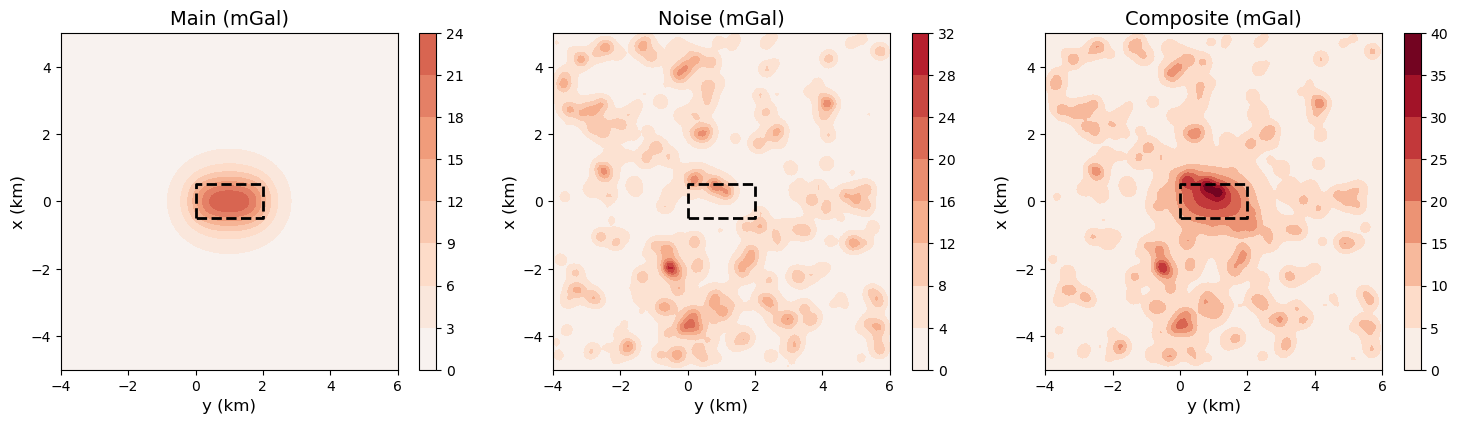

In [23]:
fields = [gz_main, gz_gn, gz]

titles = ['Main (mGal)', 'Noise (mGal)', 'Composite (mGal)']

windows = [i for i in range(1,4)]

plt.figure(figsize=(15,4))

for w, window in enumerate(windows):

    plt.subplot(1,3,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        yp.reshape(shape)*0.001, 
        xp.reshape(shape)*0.001, 
        fields[w].reshape(shape), 
        cmap='RdBu_r',
        vmin = -bounds, vmax = bounds
    )
    plt.colorbar()
    plf.model_boundaries(model_main, m2km=True)
    plt.ylim(0.001*area[0], 0.001*area[1])
    plt.xlim(0.001*area[2], 0.001*area[3])
    plt.xlabel('y (km)', fontsize=12)
    plt.ylabel('x (km)', fontsize=12)

plt.tight_layout()

plt.show()

### Comparison $\Omega$ and numerically obtained total mass

In [24]:
Omega_numerical = dx*dy*np.sum(gz)/cts.SI2MGAL

In [25]:
Omega_numerical

5703.402477201532

In [26]:
Omega

6384.245138106937

In [27]:
Omega_numerical/Omega

0.8933558085291052

### Theoretical equivalent layer

In [28]:
# compute 2D Fourier transform of U without padding
FT_gz = transforms.DFT(data=gz.reshape(shape))

In [29]:
# multiply FT_gz by the element of area to retrieve the true Fourier Transform amplitude
FT_gz *= dx*dy

# set the FT_gz equal to zero at the zero frequency
FT_gz[0,0] = 0.

In [30]:
# compute wavenumbers
kx, ky, kz = transforms.wavenumbers(FT_gz.shape, dx, dy)

In [31]:
# set the equivalent layer depth
z_layer = 300.

In [32]:
# define the continuation filter
down_continuation_filter = [filters.continuation(kz=kz, dz=z_layer-z_data)]

In [33]:
# compute the downward continued field on the layer
FT_gz_downward_layer = convolve.compute(FT_gz, down_continuation_filter)

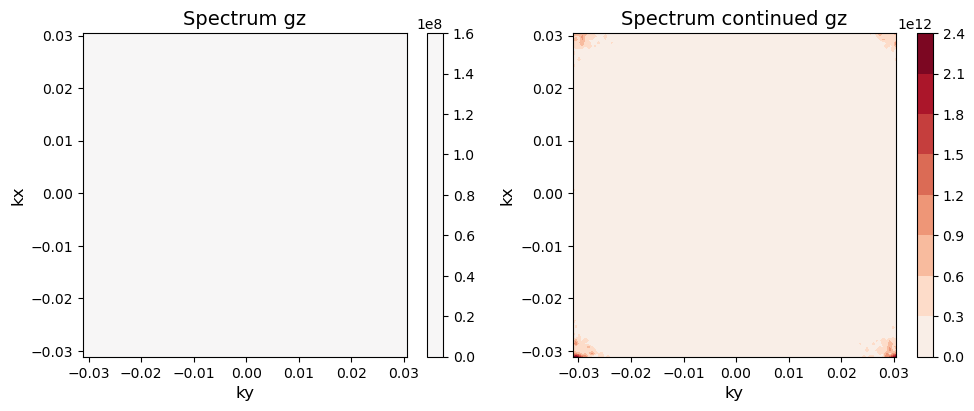

In [34]:
bounds = np.max(np.abs([np.abs(FT_gz), np.abs(FT_gz_downward_layer)]))

fields = [np.abs(FT_gz), np.abs(FT_gz_downward_layer)]

titles = ['Spectrum gz', 'Spectrum continued gz']

windows = [i for i in range(1,3)]

plt.figure(figsize=(10,4))

for w, window in enumerate(windows):

    plt.subplot(1,2,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        fftshift(ky), 
        fftshift(kx), 
        fftshift(fields[w]), 
        cmap='RdBu_r',
        vmin = -bounds, vmax = bounds
    )
    plt.colorbar()
    plt.ylim(kx.min(), kx.max())
    plt.xlim(ky.min(), ky.max())
    plt.xlabel('ky', fontsize=12)
    plt.ylabel('kx', fontsize=12)

plt.tight_layout()

plt.show()

In [35]:
# cuttoff wavenumber
kz_epsilon = np.linspace(0.001, 0.01, 30)

In [36]:
Dz = z_model_top - z_data

In [37]:
2*Dz*kz_epsilon

array([0.2001551 , 0.2622722 , 0.3243893 , 0.3865064 , 0.44862351,
       0.51074061, 0.57285771, 0.63497481, 0.69709191, 0.75920901,
       0.82132611, 0.88344321, 0.94556031, 1.00767741, 1.06979451,
       1.13191161, 1.19402871, 1.25614581, 1.31826292, 1.38038002,
       1.44249712, 1.50461422, 1.56673132, 1.62884842, 1.69096552,
       1.75308262, 1.81519972, 1.87731682, 1.93943392, 2.00155102])

In [38]:
epsilon = []
for kz_epsilon_i in kz_epsilon:
    a = 1e-7
    #epsilon.append(gammaincc(a, 2*Dz*kz_epsilon_i)*gamma(a))
    #epsilon.append(gammaincc(a, kz_epsilon_i))
    epsilon.append(gamma(a)*(1. - gammainc(a, 2*Dz*kz_epsilon_i)))
epsilon = np.array(epsilon)*(2*np.pi*(Omega)**2)/(dx*dy)

In [39]:
epsilon

array([30672.28958779, 25280.14448359, 21296.23877788, 18210.86334322,
       15744.72317009, 13728.34033523, 12051.29001587, 10637.74166601,
        9433.46899355,  8398.43905262,  7502.31551176,  6721.6141439 ,
        6037.82449725,  5436.13180672,  4904.5234047 ,  4433.14604021,
        4013.83755758,  3639.77711842,  3305.22027659,  3005.29552615,
        2735.84596503,  2493.30459321,  2274.59510863,  2077.05215382,
        1898.35691681,  1736.48412944,  1589.65890237,  1456.32066614,
        1335.09313122,  1224.75937556])

In [40]:
# compute 2D Fourier transform of gz with padding
FT_gz = transforms.DFT(data=gz.reshape(shape), pad_mode='linear_ramp')

# compute wavenumbers
kx, ky, kz = transforms.wavenumbers(FT_gz.shape, dx, dy)

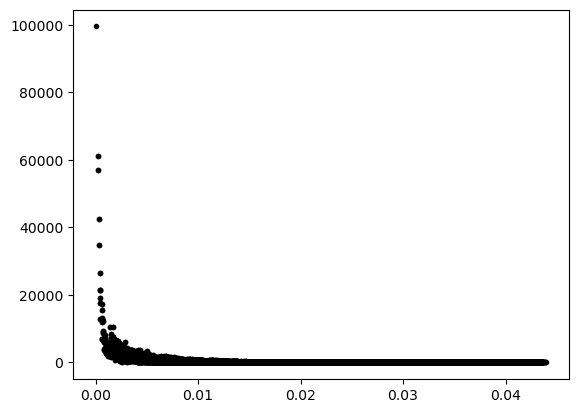

In [41]:
plt.figure()
plt.plot(kz.ravel(), np.abs(FT_gz).ravel(), 'k.')
plt.show()

In [42]:
# define the continuation filter
down_continuation_filter = filters.continuation(kz=kz, dz=z_layer-z_data)

In [43]:
gz_downward_layer = []
for kz_epsilon_i in kz_epsilon:
    # define the composite filter
    composite_filter = [
        filters.cuttof_frequency(kz, kz_epsilon_i),
        down_continuation_filter
    ]
    # compute the downward continued field in Fourier domain
    FT_gz_downward_layer = convolve.compute(FT_gz, composite_filter)
    # transform the downward continued field to space domain
    gz_downward_layer.append(transforms.IDFT(FT_gz_downward_layer, unpad=True, grid=False))

In [44]:
# theoretical equivalent layer
p_theoretical = []
for gz_down_i in gz_downward_layer:
    p_theoretical.append(((dx*dy)/(2*np.pi*cts.SI2MGAL))*gz_down_i)

In [45]:
# kernel matrix associated with the equivalent layer
G = eqlayer.kernel_matrix_monopoles(coordinates, z_layer, field='potential')

In [46]:
# list for storing the predicted gravitational field components
predicted_fields = []
for p_theoretical_i in p_theoretical:
    # compute the predicted field and update the list
    predicted_fields.append(G@p_theoretical_i)

In [47]:
error = []
for predicted_field in predicted_fields:
    residuals = predicted_field - U
    error.append(np.sum(np.abs(residuals)))
error = np.array(error)

In [48]:
error

array([163.1849005 , 197.11051429, 125.0072308 ,  76.89128284,
        69.43609482,  58.00119153,  49.71218792,  37.0593702 ,
        32.99982885,  29.87956148,  30.82945579,  39.16397252,
        36.40477479,  46.07341229,  39.00035026,  45.69140186,
        37.40959032,  40.26295527,  37.42784857,  48.21381092,
        41.87514469,  51.32426491,  32.9340078 ,  26.2535678 ,
        13.50285353,  18.10054804,  18.57007237,  17.30759444,
        25.38191736,  27.92804665])

In [49]:
epsilon

array([30672.28958779, 25280.14448359, 21296.23877788, 18210.86334322,
       15744.72317009, 13728.34033523, 12051.29001587, 10637.74166601,
        9433.46899355,  8398.43905262,  7502.31551176,  6721.6141439 ,
        6037.82449725,  5436.13180672,  4904.5234047 ,  4433.14604021,
        4013.83755758,  3639.77711842,  3305.22027659,  3005.29552615,
        2735.84596503,  2493.30459321,  2274.59510863,  2077.05215382,
        1898.35691681,  1736.48412944,  1589.65890237,  1456.32066614,
        1335.09313122,  1224.75937556])

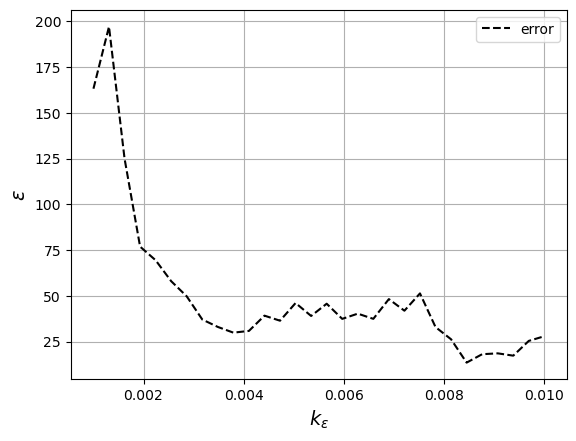

In [50]:
plt.figure()
plt.plot(kz_epsilon, error, 'k--', label='error')
#plt.plot(kz_epsilon, epsilon, 'k-', label = '$\\varepsilon$')
plt.xlabel('$k_{\\varepsilon}$', fontsize=14)
plt.ylabel('$\\varepsilon$', fontsize=14)
plt.grid()
plt.legend(loc='best')
plt.show()